In [1]:
!pip install -q kagglehub gradio

In [2]:
import os, zlib, json, shutil, numpy as np, tensorflow as tf, kagglehub

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
DATA = "/content/data"
shutil.rmtree(DATA, ignore_errors=True)
os.makedirs(DATA)

def add_dataset(root, prefix=None, must_contain=None):
    """root ke andar jis bhi folder me images hain, use ek class maan kar DATA me link karta hai."""
    n = 0
    for d, _, files in os.walk(root):
        imgs = [f for f in files if f.lower().endswith(IMG_EXT)]
        if not imgs:
            continue
        if must_contain and must_contain not in d.lower():
            continue
        cls = os.path.basename(d).strip().replace(" ", "_")
        name = f"{prefix}___{cls}" if prefix else cls
        out = os.path.join(DATA, name)
        os.makedirs(out, exist_ok=True)
        tag = zlib.crc32(d.encode()) % 10**6
        for f in imgs:
            os.symlink(os.path.join(d, f), os.path.join(out, f"{tag}_{f}"))
            n += 1
    return n

# 1) PlantVillage (color images) - 14 crops, 38 classes
pv = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
print("PlantVillage images:", add_dataset(pv, must_contain="color"))

# 2) Sugarcane - 6 classes
sc = kagglehub.dataset_download("akilesh253/sugarcane-plant-diseases-dataset")
print("Sugarcane images:", add_dataset(sc, prefix="Sugarcane"))

# 3) Crops (rice, wheat, maize...)
EXTRA_DATASETS = [
    # ("owner/dataset-slug", "Rice"),
]
for slug, crop in EXTRA_DATASETS:
    p = kagglehub.dataset_download(slug)
    print(crop, "images:", add_dataset(p, prefix=crop))

classes = sorted(os.listdir(DATA))
print("\nTotal classes:", len(classes))
print([c for c in classes if c.startswith("Sugarcane")])

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
PlantVillage images: 54305


100%|██████████| 1.00G/1.00G [00:47<00:00, 22.5MB/s]

Extracting files...


Sugarcane images: 19926

Total classes: 44
['Sugarcane___BacterialBlights', 'Sugarcane___Healthy', 'Sugarcane___Mosaic', 'Sugarcane___RedRot', 'Sugarcane___Rust', 'Sugarcane___Yellow']


In [3]:
IMG = 224
BATCH = 32
common = dict(image_size=(IMG, IMG), batch_size=BATCH, seed=42, validation_split=0.2, label_mode="int")
train_ds = tf.keras.utils.image_dataset_from_directory(DATA, subset="training", **common)
val_ds   = tf.keras.utils.image_dataset_from_directory(DATA, subset="validation", **common)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
json.dump(class_names, open("class_names.json", "w"))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
print("Classes:", NUM_CLASSES)

Found 74231 files belonging to 44 classes.
Using 59385 files for training.
Found 74231 files belonging to 44 classes.
Using 14846 files for validation.
Classes: 44


In [4]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomBrightness(0.2),
    tf.keras.layers.RandomContrast(0.2),
], name="augment")

base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = tf.keras.Input(shape=(IMG, IMG, 3))
x = augment(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 44)             │        56,364 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,314,348 (8.83 MB)

 Trainable params: 56,364 (220.17 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [5]:
cb = [tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True, monitor="val_accuracy")]
h1 = model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=cb)

Epoch 1/5
1856/1856 ━━━━━━━━━━━━━━━━━━━━ 220s 113ms/step - accuracy: 0.7820 - loss: 0.7030 - val_accuracy: 0.8681 - val_loss: 0.4097
Epoch 2/5
1856/1856 ━━━━━━━━━━━━━━━━━━━━ 135s 73ms/step - accuracy: 0.8488 - loss: 0.4487 - val_accuracy: 0.8744 - val_loss: 0.3775
Epoch 3/5
1856/1856 ━━━━━━━━━━━━━━━━━━━━ 152s 82ms/step - accuracy: 0.8574 - loss: 0.4215 - val_accuracy: 0.8873 - val_loss: 0.3368
Epoch 4/5
1856/1856 ━━━━━━━━━━━━━━━━━━━━ 135s 73ms/step - accuracy: 0.8627 - loss: 0.4106 - val_accuracy: 0.8878 - val_loss: 0.3408
Epoch 5/5
1856/1856 ━━━━━━━━━━━━━━━━━━━━ 151s 81ms/step - accuracy: 0.8646 - loss: 0.4070 - val_accuracy: 0.8920 - val_loss: 0.3325


In [6]:
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=cb)

model.save("crop_disease_model.keras")
print("Saved: crop_disease_model.keras")

Epoch 1/5
1856/1856 ━━━━━━━━━━━━━━━━━━━━ 194s 99ms/step - accuracy: 0.8220 - loss: 0.5743 - val_accuracy: 0.8962 - val_loss: 0.3006
Epoch 2/5
1856/1856 ━━━━━━━━━━━━━━━━━━━━ 181s 98ms/step - accuracy: 0.8821 - loss: 0.3456 - val_accuracy: 0.9129 - val_loss: 0.2573
Epoch 3/5
1856/1856 ━━━━━━━━━━━━━━━━━━━━ 181s 98ms/step - accuracy: 0.9006 - loss: 0.2883 - val_accuracy: 0.9229 - val_loss: 0.2243
Epoch 4/5
1856/1856 ━━━━━━━━━━━━━━━━━━━━ 182s 98ms/step - accuracy: 0.9136 - loss: 0.2487 - val_accuracy: 0.9301 - val_loss: 0.2043
Epoch 5/5
1856/1856 ━━━━━━━━━━━━━━━━━━━━ 202s 98ms/step - accuracy: 0.9213 - loss: 0.2239 - val_accuracy: 0.9337 - val_loss: 0.1928
Saved: crop_disease_model.keras


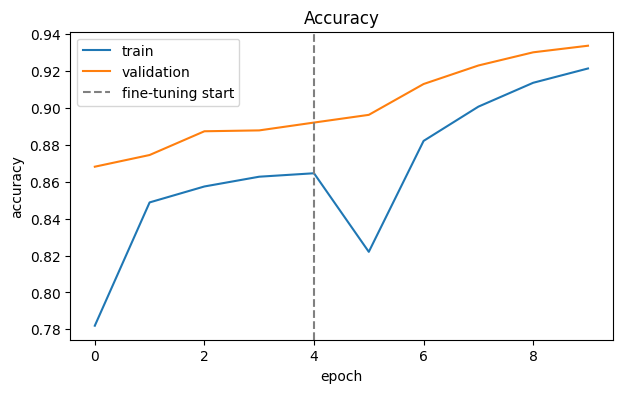

Validation accuracy: 0.933652162198572
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.984     0.940     0.962       133
                                 Apple___Black_rot      0.985     0.978     0.981       135
                          Apple___Cedar_apple_rust      1.000     0.980     0.990        51
                                   Apple___healthy      0.955     0.994     0.974       321
                               Blueberry___healthy      0.997     0.993     0.995       302
          Cherry_(including_sour)___Powdery_mildew      0.996     0.979     0.987       233
                 Cherry_(including_sour)___healthy      0.982     0.976     0.979       165
Corn_(maize)___Cercospora_leaf_spot_Gray_leaf_spot      0.851     0.843     0.847       115
                       Corn_(maize)___Common_rust_      0.992     1.000     0.996       261
               Corn_(maize)___Northern_L

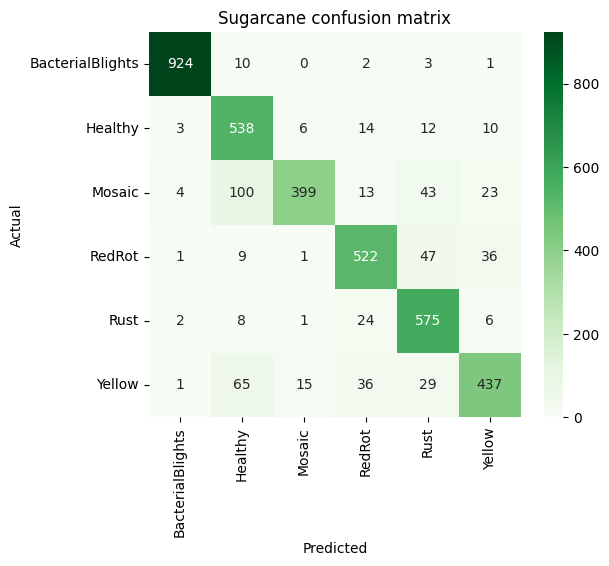

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

acc = h1.history["accuracy"] + h2.history["accuracy"]
val = h1.history["val_accuracy"] + h2.history["val_accuracy"]
plt.figure(figsize=(7,4)); plt.plot(acc, label="train"); plt.plot(val, label="validation")
plt.axvline(len(h1.history["accuracy"])-1, ls="--", c="gray", label="fine-tuning start")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.title("Accuracy")
plt.savefig("accuracy_curve.png", dpi=150, bbox_inches="tight"); plt.show()

y_true, y_pred = [], []
for xb, yb in val_ds:
    y_true += yb.numpy().tolist()
    y_pred += np.argmax(model.predict(xb, verbose=0), axis=1).tolist()

print("Validation accuracy:", np.mean(np.array(y_true) == np.array(y_pred)))
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

# Sirf sugarcane ki confusion matrix
sc_idx = [i for i, c in enumerate(class_names) if c.startswith("Sugarcane")]
mask = [t in sc_idx for t in y_true]
yt = [t for t, m in zip(y_true, mask) if m]; yp = [p for p, m in zip(y_pred, mask) if m]
cm = confusion_matrix(yt, yp, labels=sc_idx)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=[class_names[i].split("___")[1] for i in sc_idx],
            yticklabels=[class_names[i].split("___")[1] for i in sc_idx])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Sugarcane confusion matrix")
plt.savefig("sugarcane_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

In [8]:
conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
open("crop_disease_model.tflite", "wb").write(conv.convert())
print("Keras model : %.1f MB" % (os.path.getsize("crop_disease_model.keras")/1e6))
print("TFLite model: %.1f MB" % (os.path.getsize("crop_disease_model.tflite")/1e6))

Saved artifact at '/tmp/tmpe_yd7oyw'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 44), dtype=tf.float32, name=None)
Captures:
  134008163973840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163974608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163974416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163974800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163972304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163974032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163973648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134006366208272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163974224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163974992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134006366

In [9]:
import cv2

def estimate_severity(img_np):
    img = cv2.resize(np.array(img_np).astype(np.uint8), (448, 448))
    h, s, v = cv2.split(cv2.cvtColor(img, cv2.COLOR_RGB2HSV))
    fg = (((s > 35) & (v > 30)).astype(np.uint8)) * 255
    fg = cv2.morphologyEx(fg, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    cnts, _ = cv2.findContours(fg, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return None, img
    leaf = np.zeros_like(fg)
    cv2.drawContours(leaf, [max(cnts, key=cv2.contourArea)], -1, 255, -1)
    if cv2.countNonZero(leaf) < 0.05 * leaf.size:
        return None, img
    leaf = cv2.erode(leaf, np.ones((5, 5), np.uint8))
    green = (((h >= 30) & (h <= 90) & (s > 40) & (v > 40)).astype(np.uint8)) * 255
    dis = cv2.bitwise_and(leaf, cv2.bitwise_not(green))
    dis = cv2.morphologyEx(dis, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    pct = 100.0 * cv2.countNonZero(dis) / max(cv2.countNonZero(leaf), 1)
    red = img.copy()
    red[dis > 0] = (255, 0, 0)
    return pct, cv2.addWeighted(img, 0.5, red, 0.5, 0)

def severity_level(pct):
    if pct < 10:  return "(Mild)"
    if pct < 30:  return "(Moderate)"
    return "Gambhir (Severe)"

In [10]:
# (keywords, disease type, recommended active ingredients, organic / cultural measures)
# Order matters: the first matching entry is used.
MEDICINE = [
    (("mite",), "Pest (mite)",
     "Abamectin or Spiromesifen (as per product label).",
     "Neem oil spray, strong water spray on the underside of leaves."),
    (("virus", "curl", "mosaic", "yellow", "greening"), "Viral / vector-borne disease",
     "There is no direct cure for viruses. Control the insect vectors (aphid, whitefly, psyllid) with Imidacloprid or Thiamethoxam.",
     "Neem oil (5 ml/litre), remove and destroy infected plants, use disease-free seed or seedlings."),
    (("bacterial",), "Bacterial disease",
     "Copper oxychloride, together with Streptocycline (as per product label).",
     "Remove infected leaves, avoid overhead irrigation."),
    (("late_blight",), "Fungal disease (late blight)",
     "Metalaxyl + Mancozeb, or Cymoxanil + Mancozeb.",
     "Burn infected leaves, follow crop rotation."),
    (("redrot", "red_rot"), "Fungal disease (red rot)",
     "No reliable cure in a standing crop. Treat seed setts with Carbendazim or Thiophanate-methyl before planting.",
     "Uproot and destroy infected clumps, apply Trichoderma, grow resistant varieties."),
    (("rust",), "Fungal disease (rust)",
     "Propiconazole, Tebuconazole or Mancozeb.",
     "Remove infected leaves, keep good air circulation in the field."),
    (("mildew",), "Fungal disease (mildew)",
     "Wettable sulphur or Hexaconazole.",
     "Thin dense plants and improve air flow."),
    (("scab", "rot", "mold"), "Fungal disease",
     "Mancozeb, Captan or Chlorothalonil.",
     "Collect and burn fallen infected leaves and fruits."),
    (("blight", "spot", "scorch", "esca"), "Fungal disease (blight / leaf spot)",
     "Mancozeb, Copper oxychloride or Chlorothalonil.",
     "Remove infected leaves, rotate crops, apply Trichoderma or Pseudomonas bio-agents."),
]

def get_medicine(label):
    low = label.lower()
    for keys, kind, med, organic in MEDICINE:
        if any(k in low for k in keys):
            return kind, med, organic
    return "Other", "Please consult your nearest Krishi Vigyan Kendra (KVK) for this disease.", "-"

def action_by_severity(pct, kind):
    if "Viral" in kind:
        if pct >= 10:
            return "Isolate or remove the infected plant and keep the insect vectors under control."
        return "Monitor the crop and keep the insect vectors under control."
    if pct < 10:
        return "Spraying is not urgent yet. Monitor the crop and remove infected leaves. Organic measures may be enough."
    if pct < 30:
        return "Spray the recommended treatment and re-inspect after 10-15 days."
    return "Spray immediately, remove heavily infected leaves or plants, and check again after 7-10 days."

SAFETY = ("Safety: always follow the dose and waiting period printed on the product label, wear gloves and a mask, "
          "and spray in the morning or evening. This is AI-generated guidance; confirm with an agriculture expert or KVK "
          "before treating the crop.")

In [11]:
import gradio as gr
import tensorflow as tf

IMG = 224

def predict(img):
    if img is None:
        return "Please upload an image.", None, {}
    x = tf.image.resize(img, (IMG, IMG))[None, ...]
    p = model.predict(x, verbose=0)[0]
    top = p.argsort()[-3:][::-1]
    probs = {class_names[i].replace("___", " - ").replace("_", " "): float(p[i]) for i in top}
    best = class_names[top[0]]
    conf = float(p[top[0]])
    pct, overlay = estimate_severity(img)

    if conf < 0.60:
        return ("Prediction is not reliable. Please upload a clear photo of a single leaf "
                "on a plain background in good light."), overlay, probs

    crop, _, disease = best.partition("___")
    disease = disease.replace("_", " ")
    if "healthy" in best.lower():
        txt = (f"Crop: {crop}\nCondition: Healthy\nConfidence: {conf*100:.1f}%\n\n"
               "The leaf looks healthy. No treatment is needed; keep monitoring regularly.")
        return txt, overlay, probs

    kind, med, organic = get_medicine(best)
    if pct is None:
        sev_txt = "Severity: leaf could not be separated from the background (use a plain background)."
        act = "See the treatment advice below."
    else:
        sev_txt = f"Diseased area (severity): {pct:.1f}%  ->  {severity_level(pct)}"
        act = action_by_severity(pct, kind)
    txt = (f"Crop: {crop}\nDisease: {disease}  ({kind})\nConfidence: {conf*100:.1f}%\n{sev_txt}\n\n"
           f"What to do: {act}\n\nRecommended treatment: {med}\nOrganic / cultural measures: {organic}\n\n{SAFETY}")
    return txt, overlay, probs

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="numpy", label="Leaf image"),
    outputs=[gr.Textbox(label="Result", lines=14),
             gr.Image(label="Diseased area (highlighted in red)"),
             gr.Label(num_top_classes=3, label="Top 3 predictions")],
    title="Crop Leaf Disease Detection, Severity and Treatment (Sugarcane + 14 crops)",
    description="Upload a photo of a sugarcane leaf or any supported crop leaf.",
)
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3c8738d980faeb480f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [12]:
from google.colab import files
for f in ["crop_disease_model.keras", "crop_disease_model.tflite", "class_names.json", "accuracy_curve.png", "sugarcane_confusion.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
import os, json
import tensorflow as tf
from google.colab import files

json.dump(class_names, open("class_names.json", "w"))

conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
open("crop_disease_model.tflite", "wb").write(conv.convert())
print("Keras model : %.1f MB" % (os.path.getsize("crop_disease_model.keras") / 1e6))
print("TFLite model: %.1f MB" % (os.path.getsize("crop_disease_model.tflite") / 1e6))

for f in ["crop_disease_model.keras", "crop_disease_model.tflite", "class_names.json",
          "accuracy_curve.png", "sugarcane_confusion.png"]:
    if os.path.exists(f):
        files.download(f)

Saved artifact at '/tmp/tmpnfj4voiv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 44), dtype=tf.float32, name=None)
Captures:
  134008163973840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163974608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163974416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163974800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163972304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163974032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163973648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134006366208272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163974224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134008163974992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134006366

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>